In [1]:
!pip install wordcloud squarify

In [2]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import squarify

from wordcloud import WordCloud
from sklearn.preprocessing import MinMaxScaler
from google.colab import files

uploaded = files.upload()

Saving tmdb_5000_movies.csv to tmdb_5000_movies.csv


In [3]:
df = pd.read_csv('tmdb_5000_movies.csv')

print(df.head())

print("Dataset Shape:", df.shape)

print(df.info())

      budget                                             genres  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   
3            http://www.thedarkknightrises.com/   49026   
4          http://movies.disney.com/john-carter   49529   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "nam

In [4]:
#data preprocessing
df = df.drop_duplicates()

df['release_date'] = pd.to_datetime(
    df['release_date'], errors='coerce'
)

df['release_year'] = df['release_date'].dt.year

df['runtime'] = df['runtime'].fillna(df['runtime'].median())

df['genres_list'] = df['genres'].apply(
    lambda x: [g['name'] for g in ast.literal_eval(x)]
    if pd.notna(x) and x != '[]' else []
)

df['primary_genre'] = df['genres_list'].apply(
    lambda x: x[0] if len(x) > 0 else 'Unknown'
)

df = df.dropna(subset=['release_year'])

print(df.head())
print("Preprocessing completed")

      budget                                             genres  \
0  237000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
1  300000000  [{"id": 12, "name": "Adventure"}, {"id": 14, "...   
2  245000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   
3  250000000  [{"id": 28, "name": "Action"}, {"id": 80, "nam...   
4  260000000  [{"id": 28, "name": "Action"}, {"id": 12, "nam...   

                                       homepage      id  \
0                   http://www.avatarmovie.com/   19995   
1  http://disney.go.com/disneypictures/pirates/     285   
2   http://www.sonypictures.com/movies/spectre/  206647   
3            http://www.thedarkknightrises.com/   49026   
4          http://movies.disney.com/john-carter   49529   

                                            keywords original_language  \
0  [{"id": 1463, "name": "culture clash"}, {"id":...                en   
1  [{"id": 270, "name": "ocean"}, {"id": 726, "na...                en   
2  [{"id": 470, "nam

In [7]:
genre_df = df.explode('genres_list').reset_index(drop=True)

genre_df = genre_df[
    genre_df['genres_list'].notna() &
    (genre_df['genres_list'] != '')
].copy()

genre_counts = genre_df['genres_list'].value_counts()

top_genres = genre_counts.head(8).index.tolist()

print(genre_counts.head(10))

genres_list
Drama              2297
Comedy             1722
Thriller           1274
Action             1154
Romance             894
Adventure           790
Crime               696
Science Fiction     535
Horror              519
Family              513
Name: count, dtype: int64


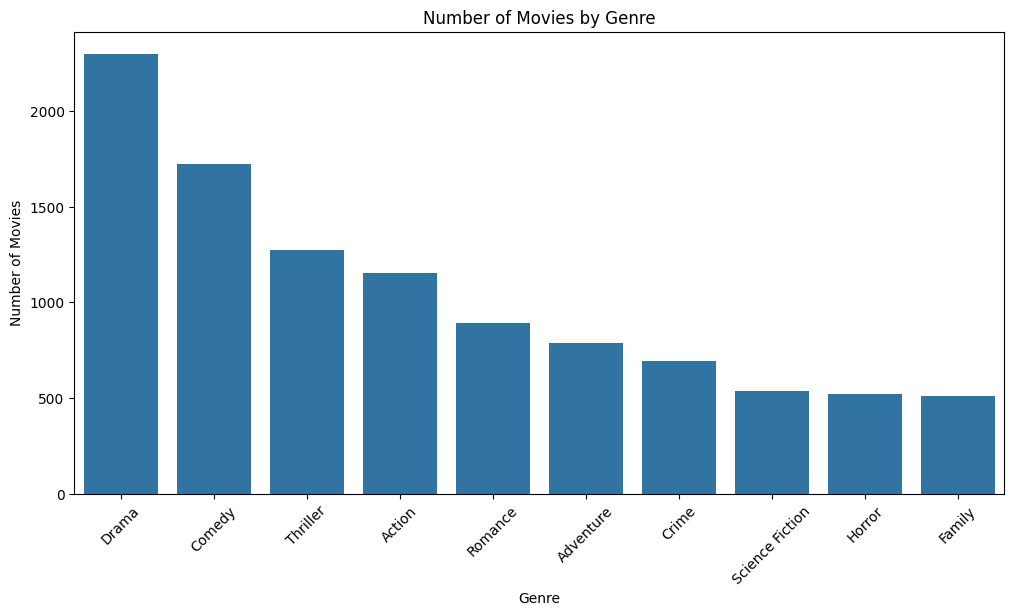

In [8]:
#creating bar chart
plt.figure(figsize=(12,6))

sns.countplot(
    data=genre_df,
    x='genres_list',
    order=genre_counts.head(10).index
)

plt.title("Number of Movies by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)

plt.show()

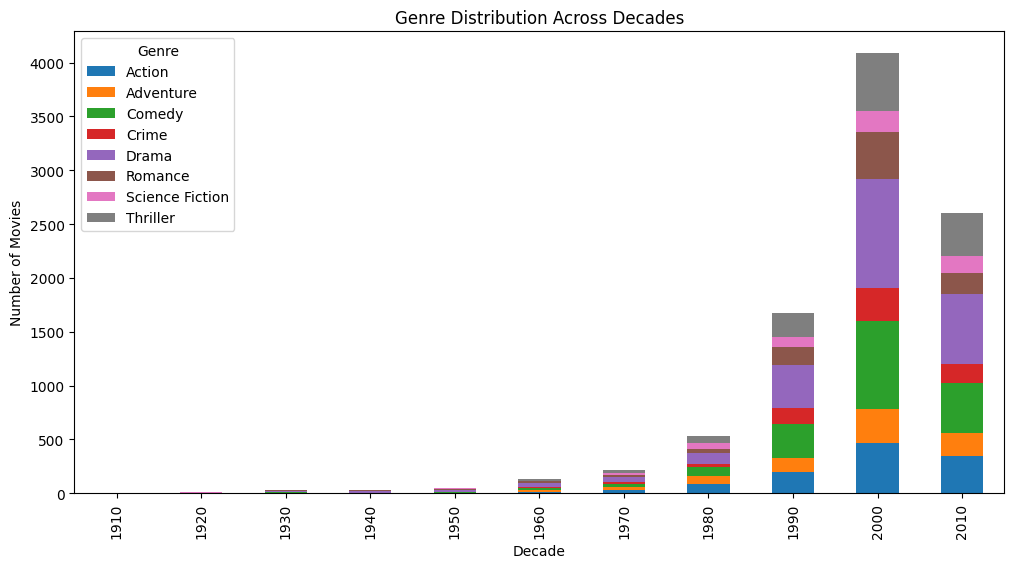

In [9]:
#stacked bar
stacked_data = genre_df[
    genre_df['genres_list'].isin(top_genres)
].copy()

stacked_data['decade'] = (
    stacked_data['release_year'] // 10 * 10
).astype(int)

pivot_data = pd.crosstab(
    stacked_data['decade'],
    stacked_data['genres_list']
)

pivot_data.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6)
)

plt.title("Genre Distribution Across Decades")
plt.xlabel("Decade")
plt.ylabel("Number of Movies")
plt.legend(title="Genre")

plt.show()

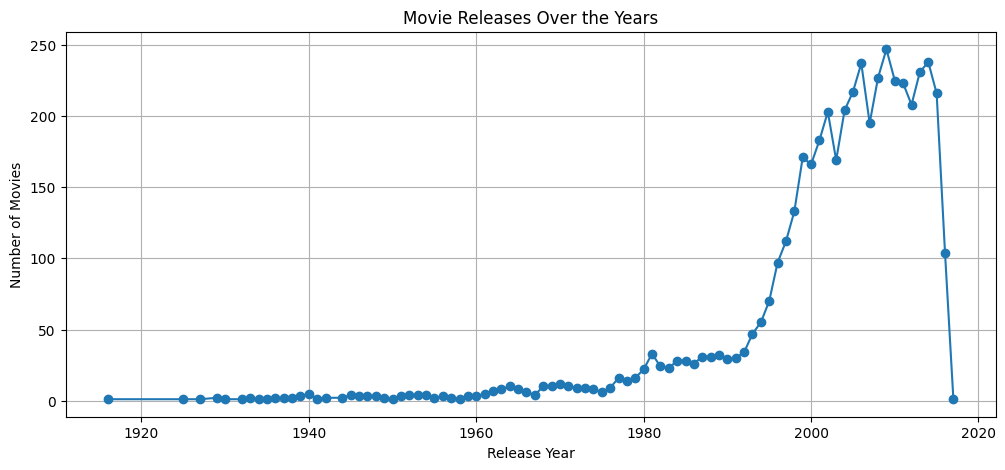

In [10]:
#line chart
yearly_movies = df.groupby('release_year').size()

plt.figure(figsize=(12,5))

plt.plot(
    yearly_movies.index,
    yearly_movies.values,
    marker='o'
)

plt.title("Movie Releases Over the Years")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")
plt.grid()

plt.show()

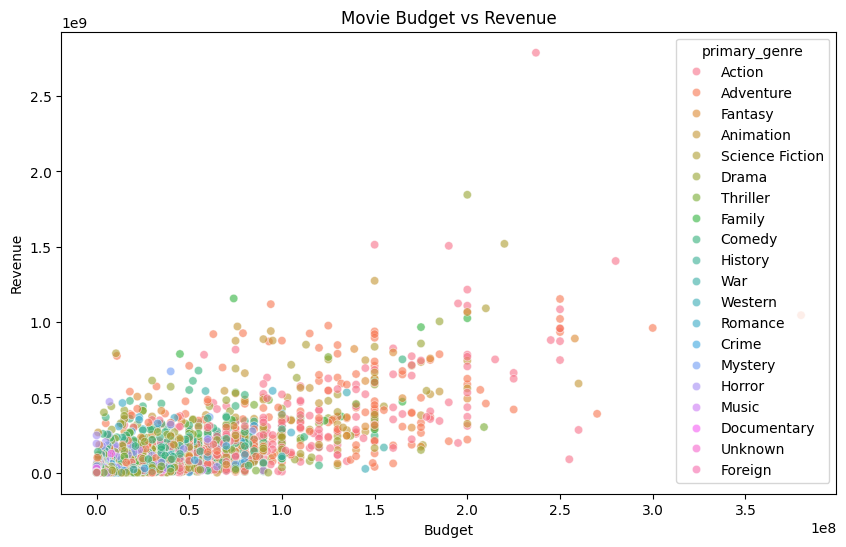

In [11]:
#scatter plot
scatter_data = df[
    (df['budget'] > 0) &
    (df['revenue'] > 0)
]

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=scatter_data,
    x='budget',
    y='revenue',
    hue='primary_genre',
    alpha=0.6
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()

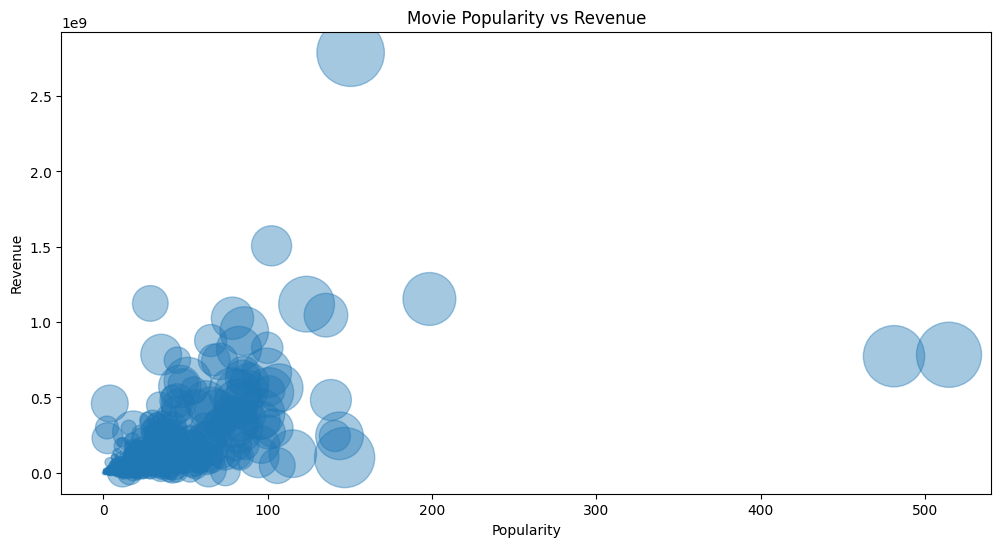

In [12]:
#bubble chart
bubble_data = df[
    (df['revenue'] > 0) &
    (df['vote_count'] > 0)
].sample(
    min(500, len(df)),
    random_state=42
)

plt.figure(figsize=(12,6))

plt.scatter(
    bubble_data['popularity'],
    bubble_data['revenue'],
    s=bubble_data['vote_count'] / 5,
    alpha=0.4
)

plt.title("Movie Popularity vs Revenue")
plt.xlabel("Popularity")
plt.ylabel("Revenue")

plt.show()

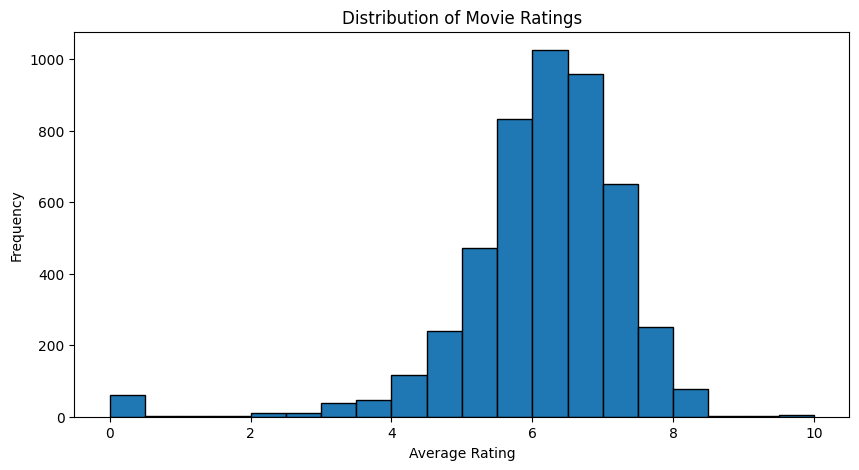

In [13]:
#histogram
plt.figure(figsize=(10,5))

plt.hist(
    df['vote_average'],
    bins=20,
    edgecolor='black'
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Frequency")

plt.show()

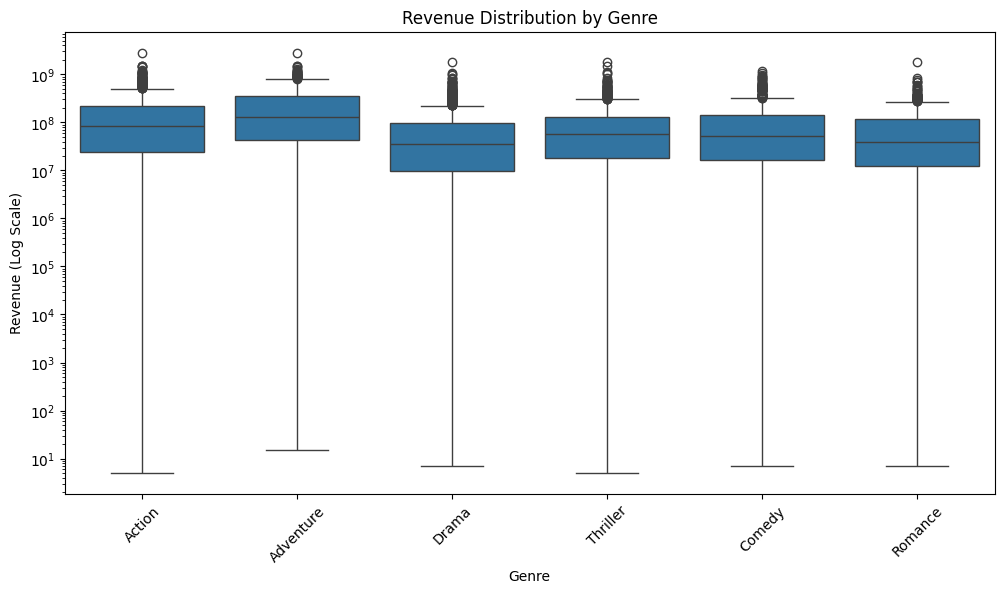

In [14]:
#boxplot
box_data = genre_df[
    (genre_df['genres_list'].isin(top_genres[:6])) &
    (genre_df['revenue'] > 0)
]

plt.figure(figsize=(12,6))

sns.boxplot(
    data=box_data,
    x='genres_list',
    y='revenue'
)

plt.yscale('log')

plt.title("Revenue Distribution by Genre")
plt.xlabel("Genre")
plt.ylabel("Revenue (Log Scale)")
plt.xticks(rotation=45)

plt.show()

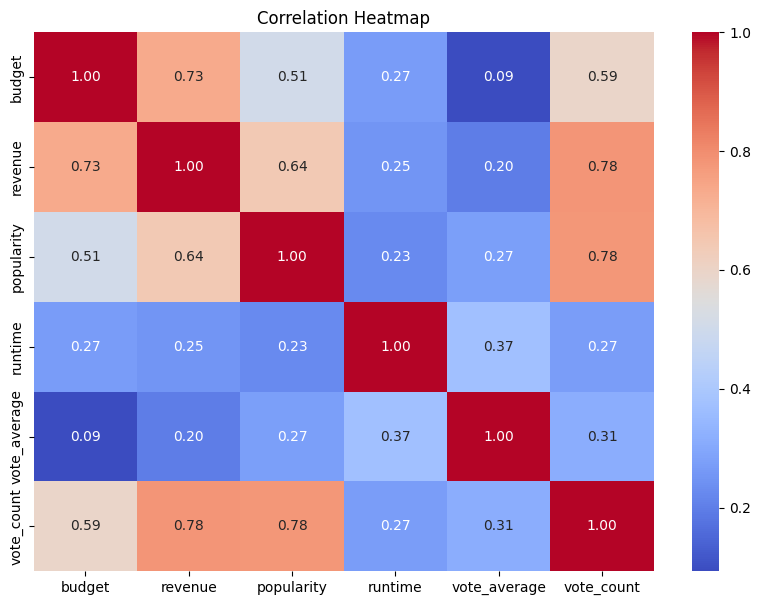

In [19]:
#heat map
numeric_data = df[
    ['budget', 'revenue', 'popularity',
     'runtime', 'vote_average', 'vote_count']
]

plt.figure(figsize=(10,7))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

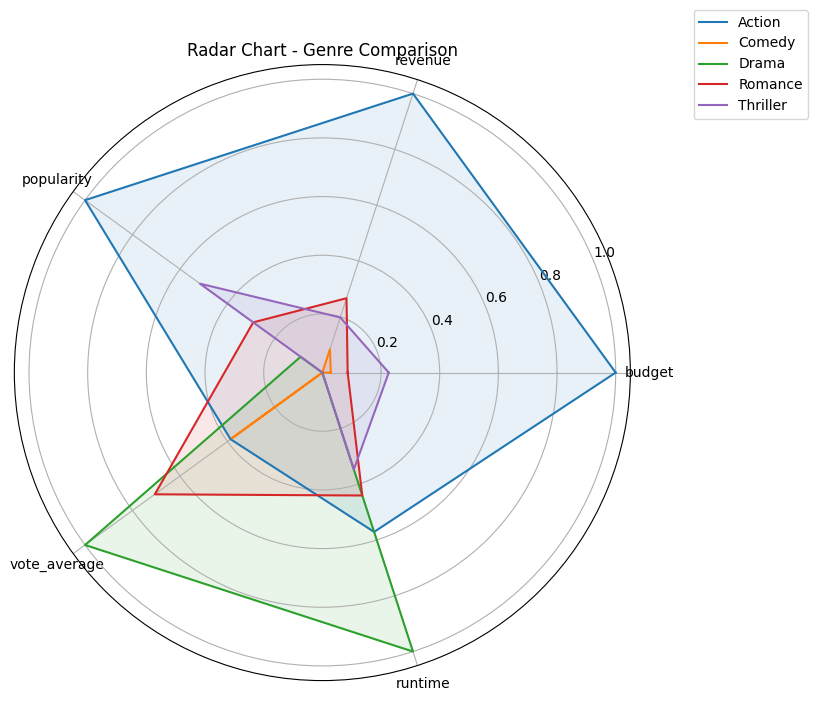

In [15]:
#radar
radar_cols = [
    'budget',
    'revenue',
    'popularity',
    'vote_average',
    'runtime'
]

radar_data = df.groupby('primary_genre')[radar_cols].mean()

radar_data = radar_data.loc[
    radar_data.index.intersection(top_genres[:5])
]

radar_scaled = pd.DataFrame(
    MinMaxScaler().fit_transform(radar_data),
    index=radar_data.index,
    columns=radar_cols
)

categories = radar_cols

angles = np.linspace(
    0, 2*np.pi, len(categories), endpoint=False
).tolist()

angles += angles[:1]

plt.figure(figsize=(8,8))

ax = plt.subplot(111, polar=True)

for genre, values in radar_scaled.iterrows():
    values = values.tolist()
    values += values[:1]

    ax.plot(angles, values, label=genre)
    ax.fill(angles, values, alpha=0.1)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories)

plt.title("Radar Chart - Genre Comparison")
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))

plt.show()

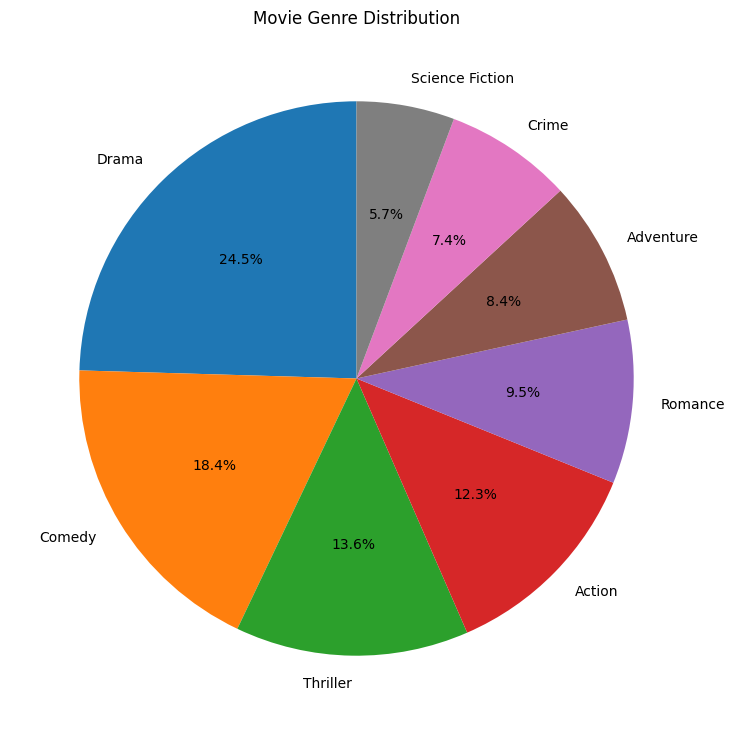

In [16]:
#pie chart
plt.figure(figsize=(9,9))

plt.pie(
    genre_counts.head(8),
    labels=genre_counts.head(8).index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Movie Genre Distribution")

plt.show()

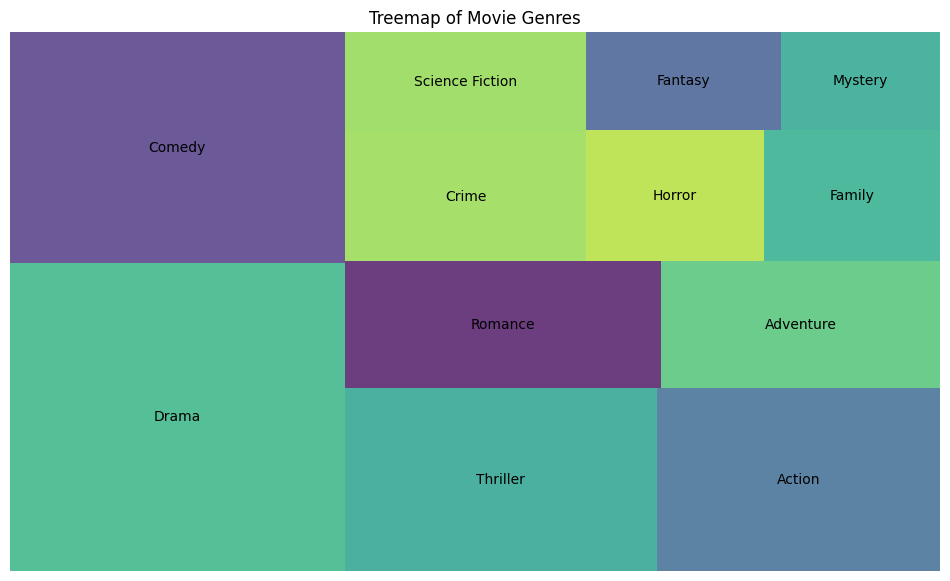

In [17]:
#tree map
plt.figure(figsize=(12,7))

squarify.plot(
    sizes=genre_counts.head(12).values,
    label=genre_counts.head(12).index,
    alpha=0.8
)

plt.title("Treemap of Movie Genres")
plt.axis('off')
plt.show()

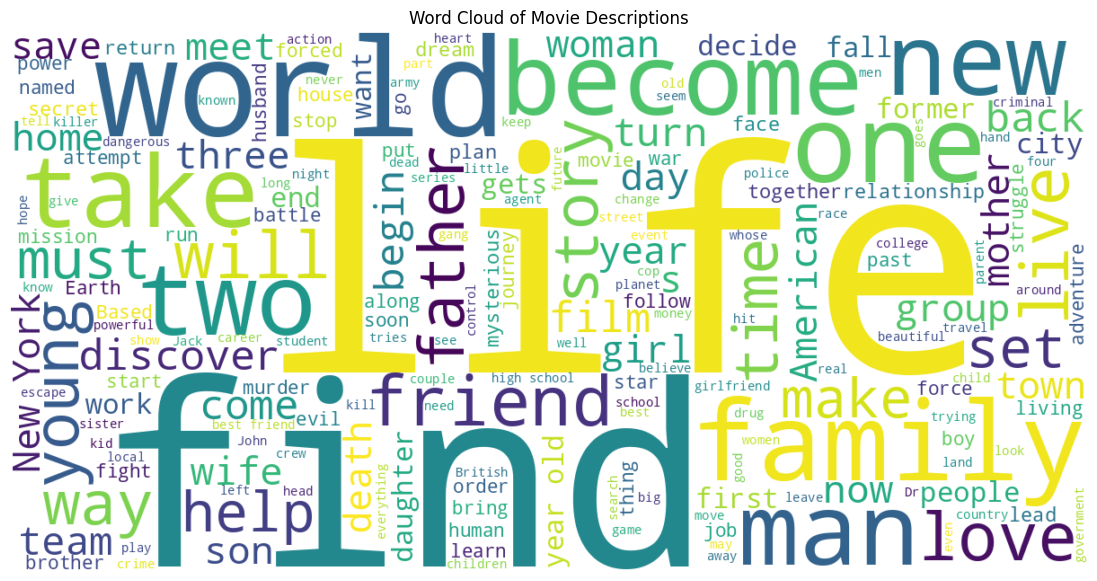

In [18]:
#word cloud
text = ' '.join(df['overview'].dropna().astype(str))

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white'
).generate(text)

plt.figure(figsize=(14,7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Movie Descriptions")
plt.show()